# [Bonus Tasks](svm_segm.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from skimage.util import view_as_blocks
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [3]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [4]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [5]:
def create_data_matrix(img, patch_sizes=patch_sizes):
    ph, pw = patch_sizes
    h, w = img.shape
    img = img[:h - h % ph, :w - w % pw]
    blocks = view_as_blocks(img, (ph, pw))
    return blocks.reshape(-1, ph * pw)

**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [6]:
def create_gt_labels_vector(gt, patch_sizes=patch_sizes):
    ph, pw = patch_sizes
    gt = gt.astype(bool)
    h, w = gt.shape
    gt = gt[:h - h % ph, :w - w % pw]
    blocks = view_as_blocks(gt, (ph, pw)).reshape(-1, ph * pw)
    frac = blocks.mean(axis=1)
    y = np.zeros(len(frac), dtype=int)
    y[frac > 0.5] = 1
    y[frac == 0] = -1
    return y

**[Task 1.3.]()** Create the SVM classifier:

In [7]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [8]:
img33 = plt.imread('data/NIH3T3/im/dna-33.png')
img44 = plt.imread('data/NIH3T3/im/dna-44.png')

X33 = create_data_matrix(img33)
X44 = create_data_matrix(img44)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [9]:
gt33 = plt.imread('data/NIH3T3/gt/33.png')
gt44 = plt.imread('data/NIH3T3/gt/44.png')

y33 = create_gt_labels_vector(gt33)
y44 = create_gt_labels_vector(gt44)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [10]:
X = np.concatenate([X33, X44])
Y = np.concatenate([y33, y44])

mask = Y != 0          
X = X[mask]
Y = Y[mask]


**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [11]:
clf.fit(X, Y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

In [12]:
def predict_image(img):
    ph, pw = patch_sizes
    X = create_data_matrix(img)                              
    labels = clf.predict(X)                                   
    grid = (labels == 1).reshape(img.shape[0] // ph,          
                                 img.shape[1] // pw)

    result = np.zeros(img.shape, dtype=bool)                 
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            result[r*ph:(r+1)*ph, c*pw:(c+1)*pw] = grid[r, c] 
    return result



Test your implementation:

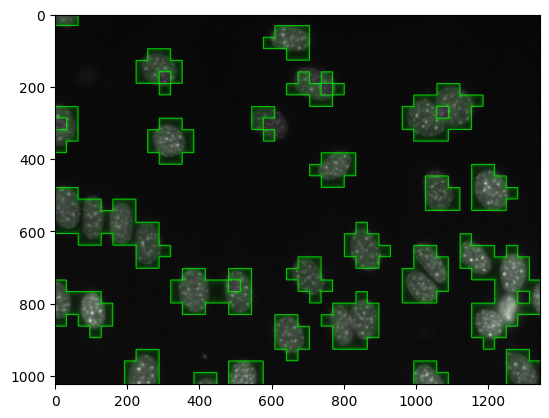

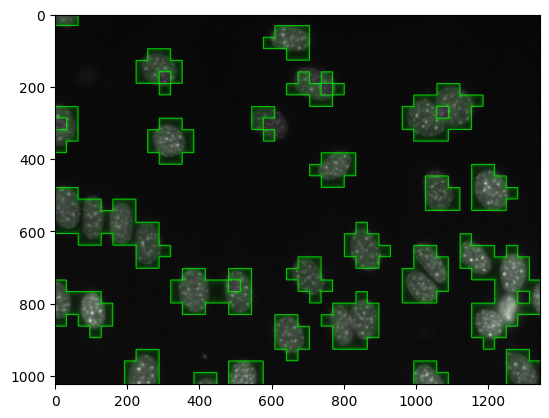

In [14]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))

Text(0.5, 1.0, 'Blend result')

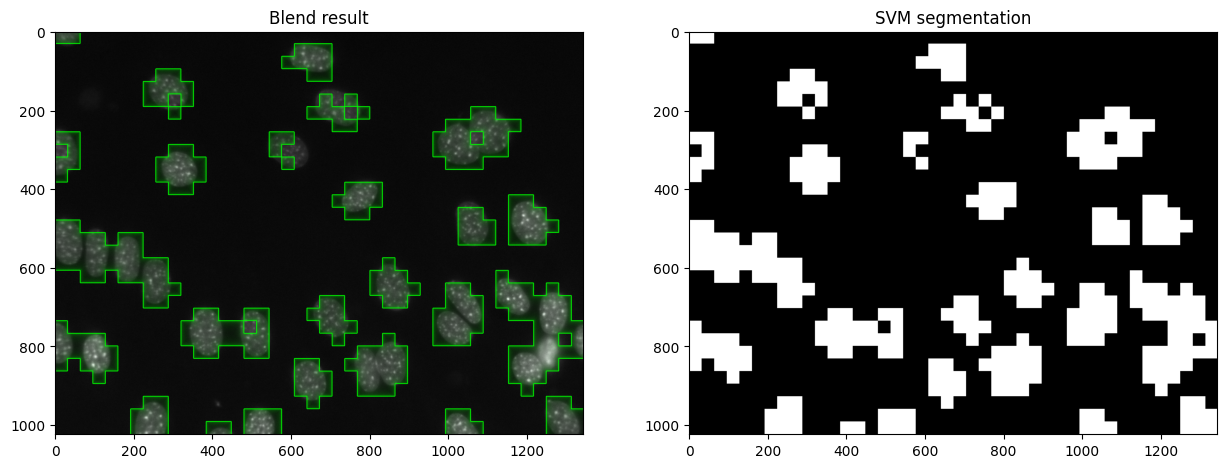

In [17]:

plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 2); plt.imshow(seg, cmap='gray'); plt.title('SVM segmentation')
plt.subplot(1, 2, 1); plt.imshow(blend_result(img, seg));  plt.title('Blend result')

**[Task 1.5.]()** Perform batch processing: